# Recovering dynamic tissue velocity from real phase-contrast MRI


## 1. Problem

Recover a full time-resolved three-component relative tissue-velocity field from four complex phase-contrast encoding images per triggered phase. The selected inverse starts after the independently executed original acquisition reconstruction.

The benchmark reconstructs every voxel of a100×67×54 volunteer volume at27triggered phases in3encoding directions. Four complex MRI images per phase are supplied. They are the output of an independently executed original acquisition reconstruction, not velocity ground truth. The selected inverse begins at those observations. It does not claim to reimplement compressed-sensing MRI, anatomical gradient probing, displacement integration or strain analysis.

The physical information is phase: for reference signal $S_0=a_0e^{i\phi_0}$ and directional signal $S_d=a_de^{i(\phi_0+\pi u_d/V)}$, their product $S_d\overline{S_0}$ removes common phase. Here$a_d$are arbitrary nonnegative signal amplitudes,$\phi_0$is background phase in radians,$u_d$is acquisition-axis velocity in m/s,and$V=0.16$m/s is the velocity encoding. Principal phase determines velocity modulo$2V$; no absolute steady-motion or unwrapped-branch truth is available.

The declared field is $v_d=M(w_d-\overline{w_d})$, where $w_d=V\operatorname{Arg}(S_d\overline{S_0})/\pi$, the bar is the arithmetic mean of all27phases at a fixed voxel and direction, and$M$is the strict public reference-magnitude support. Mean subtraction precedes this time-dependent mask, so the final masked mean can be nonzero. Positive velocity means positive acquired phase, not an independently calibrated anatomical direction.


## 2. Data

The native real volunteer data have 100 by 67 by 54 voxels and 27 phases in three encoding directions. Complex images are observations, velocity is m/s and VENC is 0.16 m/s. Independently measured anatomical gradient polarity and steady-motion truth are unavailable.

`data/raw_data.npz` contains one batch-first observation array. Its complex real and imaginary components preserve the acquired phase information; do not replace them with magnitude alone.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| encoding_images | (1, 27, 4, 54, 67, 100) | complex64 | Complex reconstructed MRI observation in arbitrary signal units; axes batch,phase,encoding,z,y,x; encoding order reference,x,y,z. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Acquisition | Deposited demonstration volunteer | - | Real observations; specific anatomy and subject details are not independently established from the deposit. |
| Matrix x,y,z | 100,67,54 | voxel | Complete original image grid, no spatial crop or resize. |
| Field of view x,y,z | 150,100,80 | mm | Relative image coordinates; absolute anatomical orientation is unavailable. |
| Voxel pitch x,y,z | 1.5,1.492537313432836,1.4814814814814814 | mm | Field of view divided by matrix size. |
| Coordinate convention | Increasing stored x,y,z indices | voxel | A relative origin may be placed at the volume center; no RAS orientation is assumed. |
| Temporal phases | 27, indexed0 through26 | phase index | Triggered periodic acquisition positions; the deposit's cardiac-image label does not identify heart anatomy. |
| Temporal phase spacing | Not supplied | s | No physical time integration or strain output is required. |
| Sequence repetition time | 0.007 | s | Sequence TR, not time between reconstructed temporal phases. |
| Echo time | 0.0047 | s | Common acquisition echo time. |
| Flip angle | 10 | degree | Supplied sequence parameter. |
| Velocity encoding V | 0.16 | m/s | Positive phase pi corresponds to this positive principal velocity. |
| Encoding count/order | 4: reference,x,y,z | - | Separate reference plus one directional encoding per component. |
| Original receive coils | 4 | coil | Combined by the acquisition reconstruction; no coil axis is present in the supplied observations. |
| Acquisition acceleration | 9 | nominal factor | Undersampled phase/partition plane with elliptical trimming. |
| Fully sampled center | 13 by10 | frequency sample | Known acquisition-reconstruction calibration extent. |
| Spectral bandwidth | 1000 | Hz/pixel | Author sequence setting. |
| Complex signal scale | Arbitrary | signal unit | No absolute spin-density or velocity-independent intensity calibration supplied. |
| Noise covariance | Not supplied | squared signal unit | No calibrated velocity confidence intervals are implied. |
| Spatial boundaries | Complete finite image grid | - | No spatial wrapping, interpolation or differentiation in the selected inverse. |


In [1]:
from pathlib import Path
import sys,os,time,json,subprocess
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT));os.chdir(ROOT)
from src.preprocessing import load_observations
from src.solvers import reconstruct
from src.visualization import make_figures
images=load_observations()
print('Real complex observation:',images.shape,images.dtype)
print('Output axes: batch,phase,direction,z,y,x; m/s. No calibrated phase interval in seconds.')


Real complex observation: (1, 27, 4, 54, 67, 100) complex64
Output axes: batch,phase,direction,z,y,x; m/s. No calibrated phase interval in seconds.


## 3. Physics

For reference $S_0=a_0e^{i\phi_0}$ and encoded $S_d=a_de^{i(\phi_0+\pi u_d/V)}$, the product $S_d\overline S_0$ cancels common phase. Amplitudes $a$ are nonnegative, $\phi_0$ radians, $u_d$ acquired-axis velocity and $V$ VENC. Principal argument determines $u_d$ only modulo $2V$.

Use all27 temporal phases and four encodings of the deposited volunteer MRI acquisition. The supplied complex images are observations for the selected velocity inverse: they were obtained from the real acquired multi-coil data using the author's acquisition reconstruction. The task begins at these complex observations, rather than at multi-coil frequency samples. No independently measured tissue velocity or scanner-direction calibration is provided.

For a voxel position r and temporal phase t, let S0 be the complex reference image and Sd the image with sensitivity to acquisition direction d, for d=1,2,3. The measurement model is


$$
S_0(r,t)=a_0(r,t)e^{i\phi_0(r,t)}+\epsilon_0(r,t),\qquad
S_d(r,t)=a_d(r,t)e^{i[\phi_0(r,t)+\pi u_d(r,t)/V]}+\epsilon_d(r,t).
$$


Here i is the imaginary unit, nonnegative amplitudes a are in arbitrary MRI signal units, common phase phi0 is in radians, u is velocity in m/s, V is the velocity encoding in m/s, and complex epsilon represents noise and acquisition-model error. Positive velocity advances the encoding phase. The data determine velocity modulo2V. Denote by P(u) its principal representative in the phase interval[-pi,pi] multiplied by V/pi. Absolute steady velocity and an unwrapped branch are not identifiable under the chosen convention.

The required relative field has the fixed convention


$$
v_d(r,t)=M(r,t)\left[P(u_d(r,t))-
\frac{1}{27}\sum_{\tau=0}^{26}P(u_d(r,\tau))\right].
$$


M is the observed support: it is1 where abs(S0) is strictly greater than0.10 times the maximum reference magnitude over the entire volume and all phases, and0 elsewhere. The temporal mean is removed before applying this time-varying support. Consequently the final masked field need not itself have temporal mean zero. This convention expresses periodic relative motion, not independently calibrated absolute tissue motion. The acquired encoding directions are labeled x,y,z; no anatomical right/anterior/superior sign assignment is implied.


## 4. Method

The direct inverse scales principal product phase by VENC/pi, subtracts each voxel/direction's 27-phase mean, then applies the time-dependent reference-magnitude support. This exact ordering defines relative motion; it neither unwraps phase nor recovers absolute steady velocity.

Complex products between an encoded image and the conjugate reference cancel their common phase. The principal argument gives a direct phase-contrast inverse after conversion with V. A fixed temporal gauge separates oscillatory relative motion from its unidentifiable constant component. Use the observation-derived support consistently; phase near negligible signal can be unstable. This inverse is closed form and needs no artificial iteration or training.


## 5. Results

The complete active path retains all 108 encoding volumes, original/local sections, orthogonal component views, high-signal summaries, full extrema and independent complex128 phasor consistency. Fresh 5%, 10%, 20% supports and no-centering control expose coverage and gauge effects.

### Complete active inverse and independent evaluation

The next cell reconstructs the complete bound observations using only cleaned NumPy functions. No original reconstruction is substituted as the fresh field. Its principal-angle convention, float32 storage and temporal averaging order match the selected source. The independent evaluator checks all3components, every voxel/phase, fixed support and complex-phasor consistency. Original-method agreement is numerical reproducibility, not measured tissue accuracy.

### Actual sensitivity comparisons and separately identified original measurements

The public method uses reference magnitude strictly above10%of its global maximum. We actively reconstruct5%and20%support variants to expose the tradeoff between coverage and fragile weak-signal phase. A separate run omits temporal centering to show that changing the gauge changes the estimated quantity; it is not an alternative estimate of the same absolute truth. No additional synthetic benchmark observations are generated.

Captured original xy/xz/yz sections and full-volume temporal summaries are comparison measurements from the completed original raw-acquisition/velocity run. The first exploratory BARTHEAD run failed and is not the oracle. The successful published-release run completed all108volumes; identical-command binary retries are documented privately. No missing volume or method is filled with zero.

### Spatial fields, temporal behavior and physical limits

All observation and reconstruction panels use native pixels, with millimetre coordinate scales. Signed component maps use a shared±3cm/s display range to reveal tissue-scale motion; the complete in-support histogram shows the larger noisy extrema, and the evaluator always scores the full unmodified arrays. Orthogonal sections demonstrate3Dcoverage; the high-signal summary region is selected only from observed reference magnitude, not anatomy or hidden velocity.

Original/fresh difference maps report actual backend rounding in nm/s. Source/source self-comparison is not presented as an error bound on true motion. Independent complex128phasor closure checks the declared velocity inverse after its fixed public temporal gauge. Low-signal phase, phase aliasing, acquisition artifacts, absent gradient-polarity calibration and loss of steady motion remain limitations.


In [2]:
start=time.perf_counter()
result,diagnostics=reconstruct(images)
standard_seconds=time.perf_counter()-start
output=ROOT/'output/reconstruction.npz';output.parent.mkdir(exist_ok=True)
np.savez_compressed(output,**result)
command=[sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(output),'--report',str(ROOT/'output/judge_report.json')]
judged=subprocess.run(command,capture_output=True,text=True)
print(judged.stdout,judged.stderr)
assert judged.returncode==0
report=json.loads((ROOT/'output/judge_report.json').read_text())
print(json.dumps(dict(runtime_seconds=standard_seconds,**report),indent=2))


 
{
  "runtime_seconds": 1.6298953000004985,
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 0.9999999999998646,
    "nrmse": 2.0920382841155924e-09,
    "x_ncc": 0.9999999999999399,
    "x_nrmse": 1.7025534097473565e-09,
    "y_ncc": 0.9999999999999128,
    "y_nrmse": 2.3442871104635158e-09,
    "z_ncc": 0.9999999999999151,
    "z_nrmse": 2.2956571282445864e-09,
    "phase_phasor_rms": 2.2264118676856452e-08,
    "outside_mask_max": 0.0
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.9999995
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "x_ncc": {
      "comparison": ">=",
      "boundary": 0.9999995
    },
    "x_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "y_ncc": {
      "comparison": ">=",
      "boundary": 0.9999995
    },
    "y_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "z_ncc": {
      "comparison": ">=",
      "boundary": 0.9999995
    

In [3]:
comparisons={.1:result};comparison_times={}
for fraction in [.05,.2]:
    start=time.perf_counter()
    comparisons[fraction],_=reconstruct(images,mask_fraction=fraction)
    comparison_times[str(fraction)]=time.perf_counter()-start
start=time.perf_counter()
comparisons['uncentered'],_=reconstruct(images,remove_temporal_mean=False)
comparison_times['uncentered']=time.perf_counter()-start
with np.load(ROOT/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as z:
    upstream={k:z[k] for k in z.files}
print('Fresh complete comparison runtimes:',comparison_times)


Fresh complete comparison runtimes: {'0.05': 2.7650100000028033, '0.2': 2.8559353000018746, 'uncentered': 2.78677880000032}


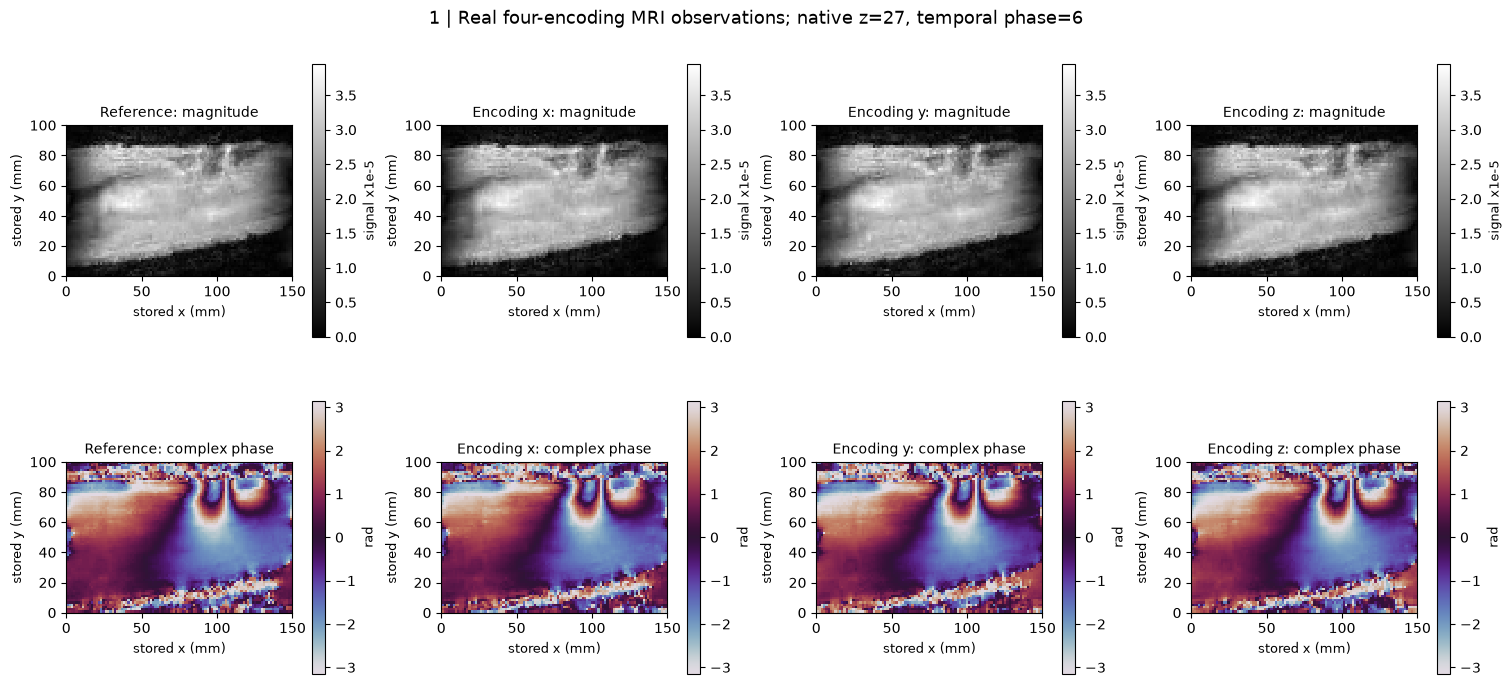

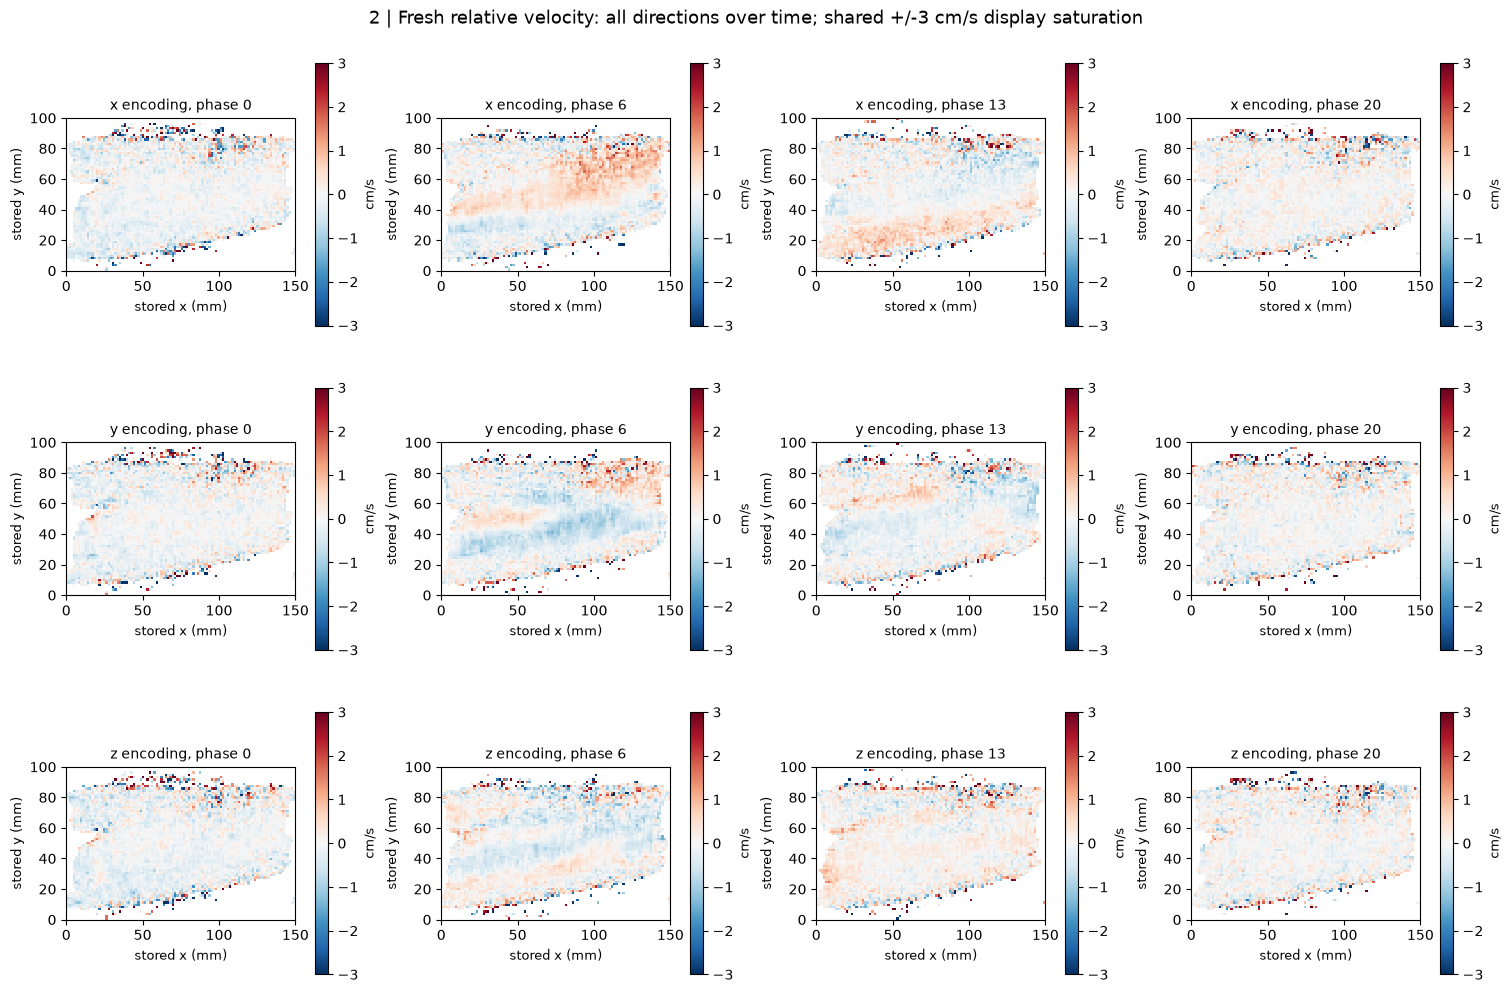

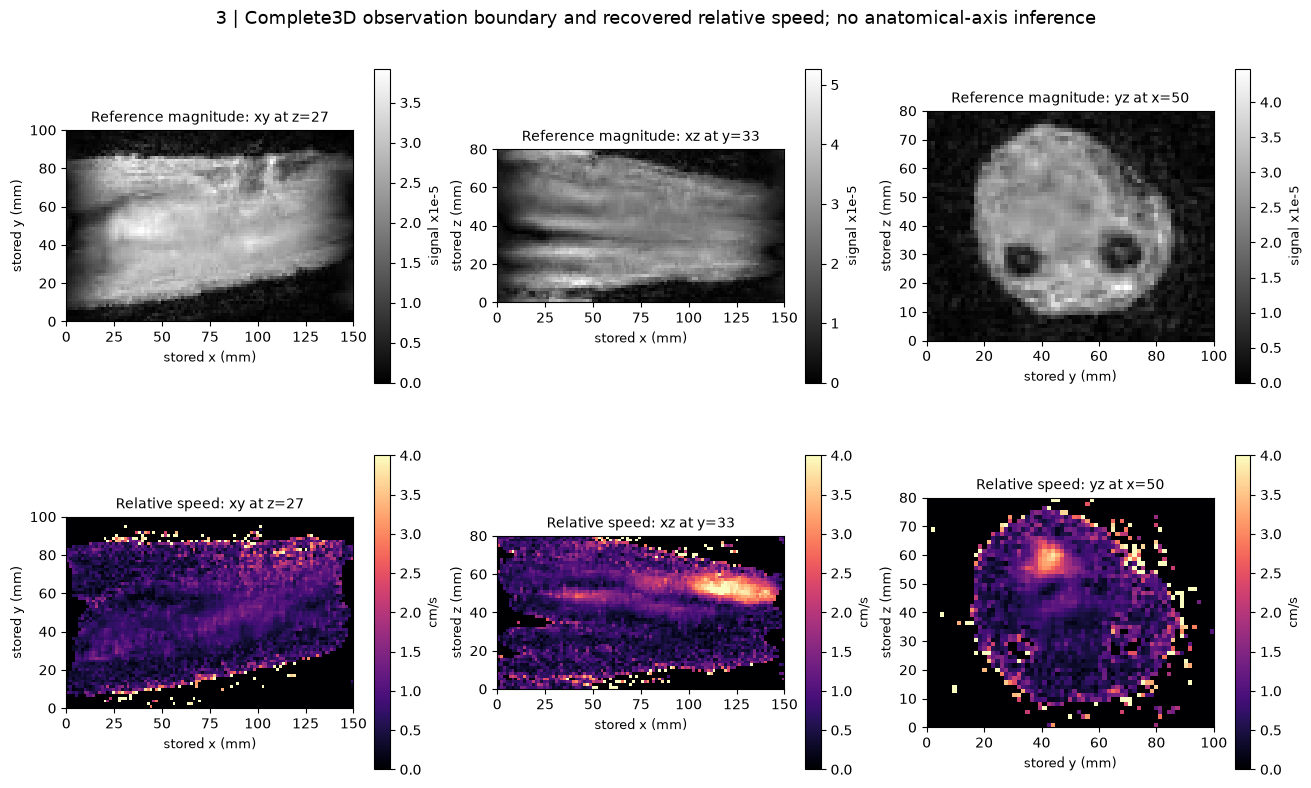

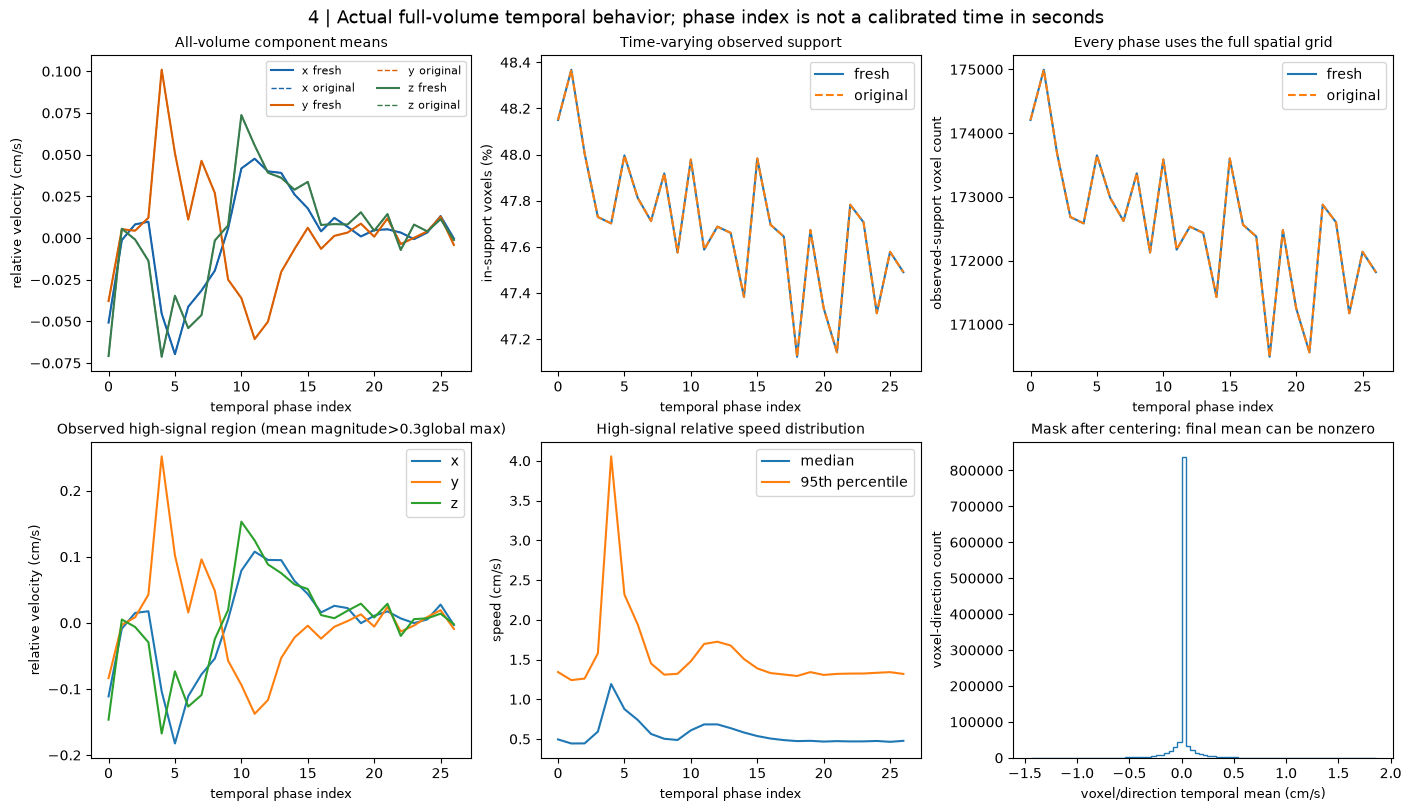

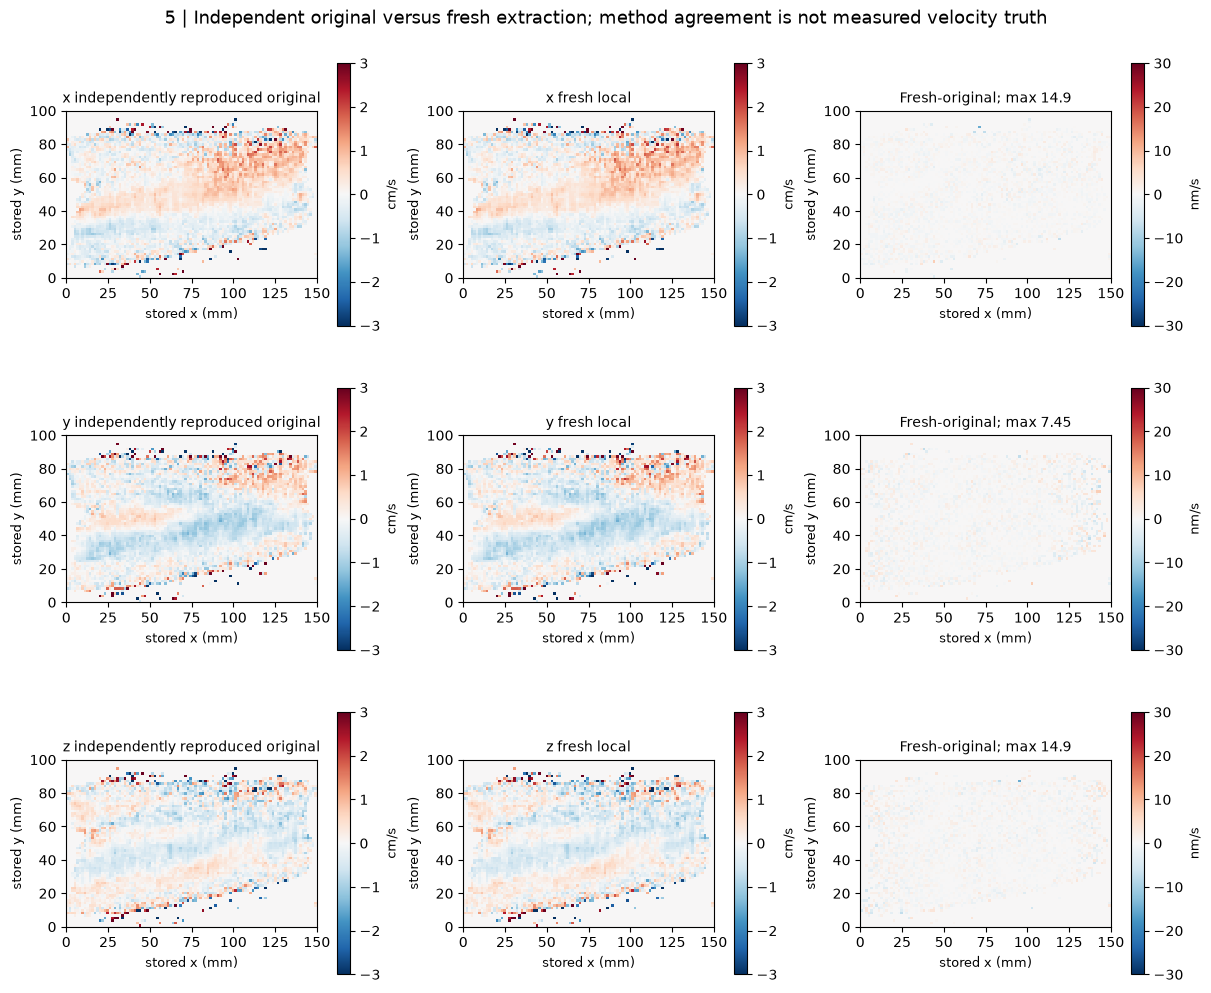

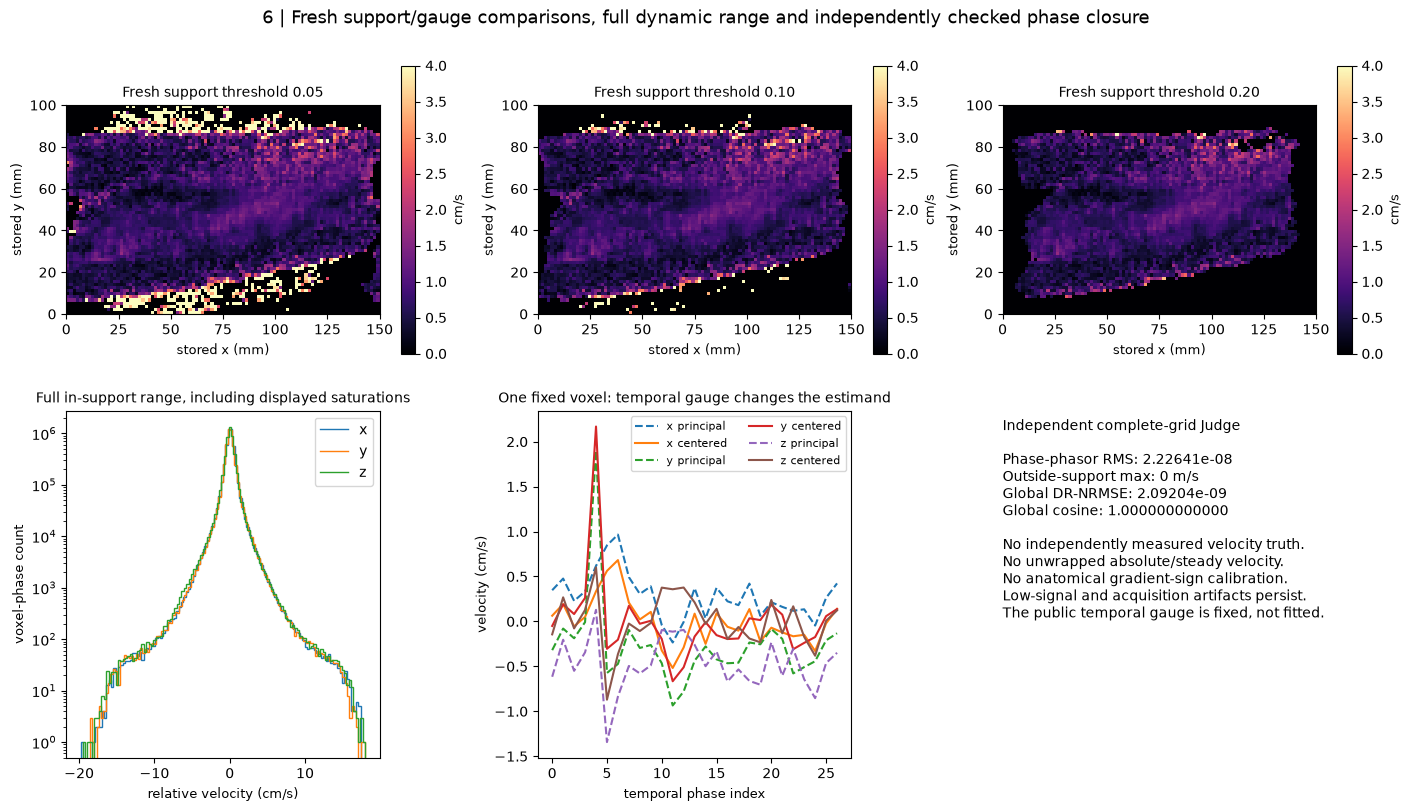

Displayed 6 actual scientific groups. All27phases and3directions reconstructed.


In [4]:
export=os.environ.get('IMAGING101_FIGURE_DIR')
figures=make_figures(images,result,diagnostics,upstream,comparisons,report,export_dir=export)
for fig in figures:
    display(fig)
    plt.close(fig)
if export:
    destination=Path(export)
    (destination/'fresh_execution.json').write_text(json.dumps(dict(standard_seconds=standard_seconds,comparison_seconds=comparison_times,metrics=report['metrics'],output_shape=list(result['reconstruction'].shape),output_dtype=str(result['reconstruction'].dtype)),indent=2))
print('Displayed',len(figures),'actual scientific groups. All27phases and3directions reconstructed.')


## 6. Conclusion

The retained results support reproducible relative-velocity recovery on the declared support. Weak-signal phase, aliasing, acquisition artifacts and absent anatomical polarity calibration prevent absolute physiological-motion or clinical claims.


The selected phase-contrast inverse actively recovers a full3Dtime-resolved relative vector field and passes independently implemented observation and reference checks. Its direct complex-product mathematics needs no artificial iteration. Support and gauge comparisons show which information is discarded or becomes unstable. This task establishes reproducible relative-velocity reconstruction; it does not establish a clinical diagnosis, anatomical sign convention, absolute steady velocity or measured physiological truth.
